## 0. Kütüphaneler

In [435]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1.Veri Edinimi

In [436]:
df = pd.read_csv('OnlineRetail.csv', encoding='ISO-8859-1', dtype={'CustomerID': str})

## 2. Veri İnceleme ve Ön işleme

In [437]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom


In [438]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  str    
 7   Country      541909 non-null  str    
dtypes: float64(1), int64(1), str(6)
memory usage: 33.1 MB


In [439]:
for i in df.columns:
    null_rate = df[i].isna().sum() / len(df) * 100
    if null_rate > 0 :
        print("{} null rate: {}%".format(i,round(null_rate,2)))

Description null rate: 0.27%
CustomerID null rate: 24.93%


In [440]:
df.nunique()

InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

In [441]:
for i in df.columns:
    nunique_rate = df[i].nunique() / len(df) * 100
    if nunique_rate > 0 :
        print("{} nunique_rate: {}%".format(i,round(nunique_rate,2)))

InvoiceNo nunique_rate: 4.78%
StockCode nunique_rate: 0.75%
Description nunique_rate: 0.78%
Quantity nunique_rate: 0.13%
InvoiceDate nunique_rate: 4.29%
UnitPrice nunique_rate: 0.3%
CustomerID nunique_rate: 0.81%
Country nunique_rate: 0.01%


In [442]:
df= df.dropna(subset=['CustomerID'])

In [443]:
df2=df[df["Quantity"] < 0]
df2.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548,United Kingdom


In [444]:
silinecekunitprice = df[df["UnitPrice"] <= 0].index
df=df.drop(silinecekunitprice)
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom


In [445]:
df["TotalPrice"] = df["UnitPrice"] * df["Quantity"]
df["TotalPrice"].head()

0    15.30
1    20.34
2    22.00
3    20.34
4    20.34
Name: TotalPrice, dtype: float64

In [446]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], dayfirst=True, errors="coerce",format='mixed')
df['Year']=df['InvoiceDate'].dt.year
df['Month']=df['InvoiceDate'].dt.month.astype('Int64')
df['day']=df['InvoiceDate'].dt.day
df['DayOfWeek']=df['InvoiceDate'].dt.day_name()
df['Hour']=df['InvoiceDate'].dt.hour.astype('Int64')
df.head()
df.info()

<class 'pandas.DataFrame'>
Index: 406789 entries, 0 to 541908
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    406789 non-null  str           
 1   StockCode    406789 non-null  str           
 2   Description  406789 non-null  str           
 3   Quantity     406789 non-null  int64         
 4   InvoiceDate  406789 non-null  datetime64[us]
 5   UnitPrice    406789 non-null  float64       
 6   CustomerID   406789 non-null  str           
 7   Country      406789 non-null  str           
 8   TotalPrice   406789 non-null  float64       
 9   Year         406789 non-null  int32         
 10  Month        406789 non-null  Int64         
 11  day          406789 non-null  int32         
 12  DayOfWeek    406789 non-null  str           
 13  Hour         406789 non-null  Int64         
dtypes: Int64(2), datetime64[us](1), float64(2), int32(2), int64(1), str(6)
memory usage: 44.2 MB


In [447]:
ulkeozet= df.groupby(['Country'])['CustomerID']
ulkeozet.describe()

,count,unique,top,freq
Country,,,,
Australia,1256,9,12415,776
Austria,401,11,12360,129
Bahrain,17,2,12355,13
Belgium,2069,25,12362,274
Brazil,32,1,12769,32
Canada,151,4,17444,135
Channel Islands,758,9,14936,366
Cyprus,622,8,12359,254
Czech Republic,30,1,12781,30


## Keşifsel Veri Analizi (EDA)

In [448]:
df_ing_dis= df.groupby('Country')["TotalPrice"].sum().sort_values(ascending=False).iloc[1:].reset_index()
df_ing_dis.head()

,Country,TotalPrice
0,Netherlands,284661.54
1,EIRE,250285.22
2,Germany,221698.21
3,France,196712.84
4,Australia,137077.27


<Axes: xlabel='TotalPrice', ylabel='Country'>

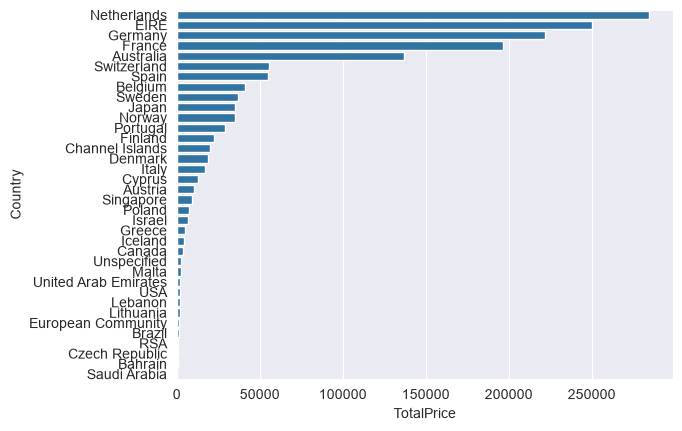

In [449]:
sns.barplot(x="TotalPrice", y="Country", data=df_ing_dis,orient="h")

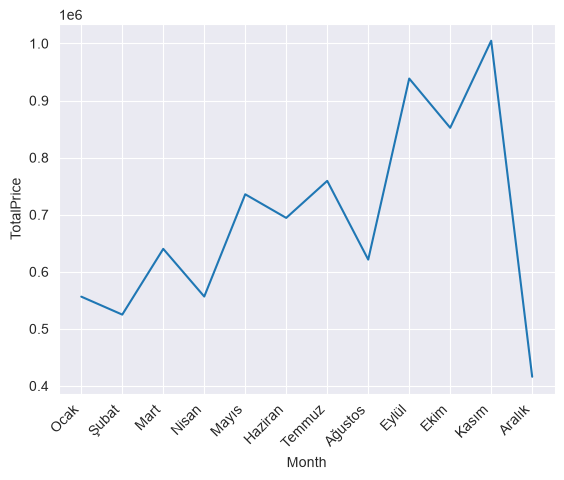

In [450]:
month_map = {
    1: 'Ocak', 2: 'Şubat', 3: 'Mart', 4: 'Nisan',
    5: 'Mayıs', 6: 'Haziran', 7: 'Temmuz', 8: 'Ağustos',
    9: 'Eylül', 10: 'Ekim', 11: 'Kasım', 12: 'Aralık'
}
df['Month'] = df['Month'].map(month_map)
months_order = ['Ocak', 'Şubat', 'Mart', 'Nisan', 'Mayıs', 'Haziran',
                'Temmuz', 'Ağustos', 'Eylül', 'Ekim', 'Kasım', 'Aralık']
df['Month'] = pd.Categorical(df['Month'], categories=months_order, ordered=True)

month_top=df.groupby('Month')['TotalPrice'].sum().reset_index()
sns.lineplot(x="Month", y="TotalPrice", data=month_top)
plt.xticks(rotation=45, ha="right")
plt.show()

In [451]:

day_map = {
    'Monday': 'Pzt',
    'Tuesday': 'Sali',
    'Wednesday': 'Crs',
    'Thursday': 'Prs',
    'Friday': 'Cuma',
    'Saturday': 'Cmt',
    'Sunday': 'Pzr'
}
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name().map(day_map)
days_order = ['Pzt', 'Sali', 'Crs', 'Prs', 'Cuma', 'Cmt', 'Pzr']
df['DayOfWeek'] = pd.Categorical(df['DayOfWeek'], categories=days_order, ordered=True)

<Axes: xlabel='Hour', ylabel='DayOfWeek'>

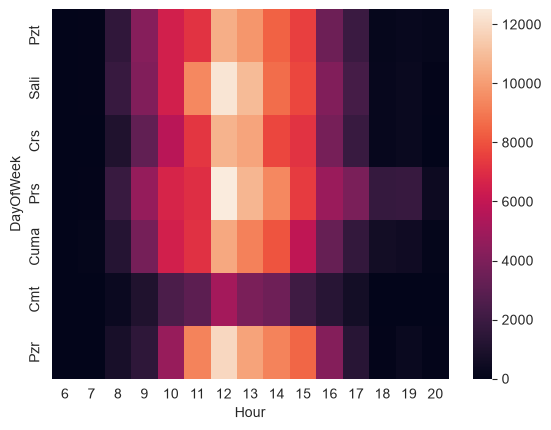

In [452]:
heatmap_data = df.pivot_table(
    index='DayOfWeek',
    columns='Hour',
    values='InvoiceNo',
    aggfunc='count',
    fill_value=0,
)
sns.heatmap(heatmap_data)

In [453]:
en_cok_satis=df["Description"].explode().dropna().str.strip()
en_cok_satis = en_cok_satis[
    (en_cok_satis != "") &
    (en_cok_satis.str.lower() != "unknown")
]

en_cok_satis=(en_cok_satis.value_counts().head(20))
en_cok_satis

Description
WHITE HANGING HEART T-LIGHT HOLDER    2070
REGENCY CAKESTAND 3 TIER              1904
JUMBO BAG RED RETROSPOT               1662
ASSORTED COLOUR BIRD ORNAMENT         1418
PARTY BUNTING                         1415
LUNCH BAG RED RETROSPOT               1358
SET OF 3 CAKE TINS PANTRY DESIGN      1232
POSTAGE                               1196
LUNCH BAG  BLACK SKULL.               1126
PACK OF 72 RETROSPOT CAKE CASES       1080
PAPER CHAIN KIT 50'S CHRISTMAS        1029
SPOTTY BUNTING                        1029
LUNCH BAG SPACEBOY DESIGN             1021
LUNCH BAG CARS BLUE                   1012
NATURAL SLATE HEART CHALKBOARD         997
HEART OF WICKER SMALL                  996
LUNCH BAG PINK POLKADOT                977
JAM MAKING SET WITH JARS               973
REX CASH+CARRY JUMBO SHOPPER           955
LUNCH BAG SUKI DESIGN                  950
Name: count, dtype: int64

<Axes: xlabel='count', ylabel='Description'>

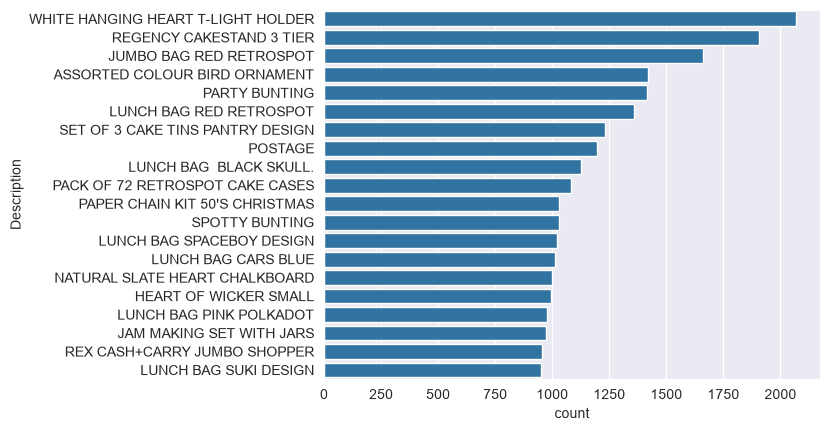

In [454]:
sns.barplot(en_cok_satis,orient='h')

In [455]:
mbg=(df[df['Quantity'] > 0].groupby('CustomerID')['TotalPrice'].sum().reset_index())
osb=(df[df['Quantity'] > 0].groupby('InvoiceNo')['TotalPrice'].sum().reset_index())
osb.head()

,InvoiceNo,TotalPrice
0,536365,139.12
1,536366,22.20
2,536367,278.73
3,536368,70.05
4,536369,17.85


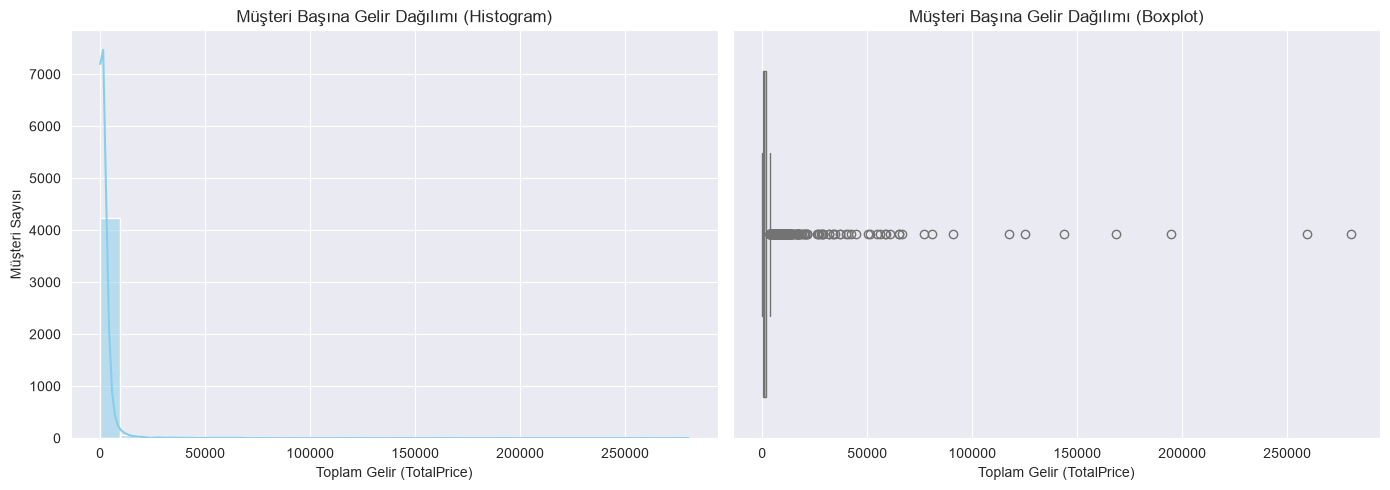

In [456]:
#Müşteri Başına Gelir Dağılımı
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(mbg['TotalPrice'], ax=axes[0], kde=True, bins=30, color='skyblue')
axes[0].set_title('Müşteri Başına Gelir Dağılımı (Histogram)')
axes[0].set_xlabel('Toplam Gelir (TotalPrice)')
axes[0].set_ylabel('Müşteri Sayısı')

sns.boxplot(x=mbg['TotalPrice'], ax=axes[1], color='lightgreen')
axes[1].set_title('Müşteri Başına Gelir Dağılımı (Boxplot)')
axes[1].set_xlabel('Toplam Gelir (TotalPrice)')

plt.tight_layout()
plt.show()

#### Çok sağa çarpık oldu küçük müşteriye ayrıntılı bakalım birde

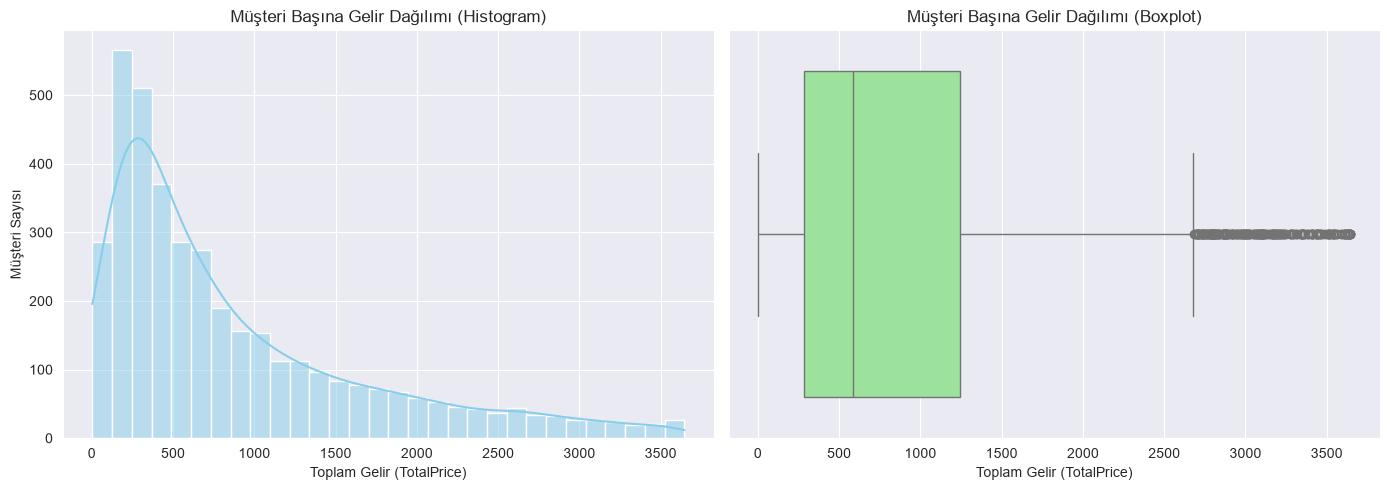

In [457]:
q_9 = mbg['TotalPrice'].quantile(0.9)
filtered_rev = mbg[mbg['TotalPrice'] <= q_9]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(filtered_rev['TotalPrice'], ax=axes[0], kde=True, bins=30, color='skyblue')
axes[0].set_title('Müşteri Başına Gelir Dağılımı (Histogram)')
axes[0].set_xlabel('Toplam Gelir (TotalPrice)')
axes[0].set_ylabel('Müşteri Sayısı')

sns.boxplot(x=filtered_rev['TotalPrice'], ax=axes[1], color='lightgreen')
axes[1].set_title('Müşteri Başına Gelir Dağılımı (Boxplot)')
axes[1].set_xlabel('Toplam Gelir (TotalPrice)')

plt.tight_layout()
plt.show()

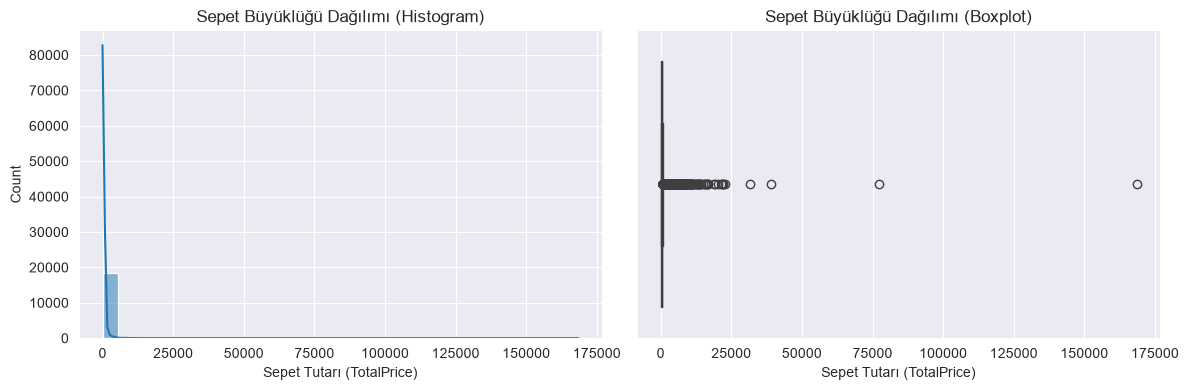

In [458]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(osb['TotalPrice'], ax=axes[0], kde=True, bins=30)
axes[0].set_title('Sepet Büyüklüğü Dağılımı (Histogram)')
axes[0].set_xlabel('Sepet Tutarı (TotalPrice)')

sns.boxplot(x=osb['TotalPrice'], ax=axes[1])
axes[1].set_title('Sepet Büyüklüğü Dağılımı (Boxplot)')
axes[1].set_xlabel('Sepet Tutarı (TotalPrice)')

plt.tight_layout()
plt.show()

#### Yine küçük alıcıya ayrıntılı bakalım

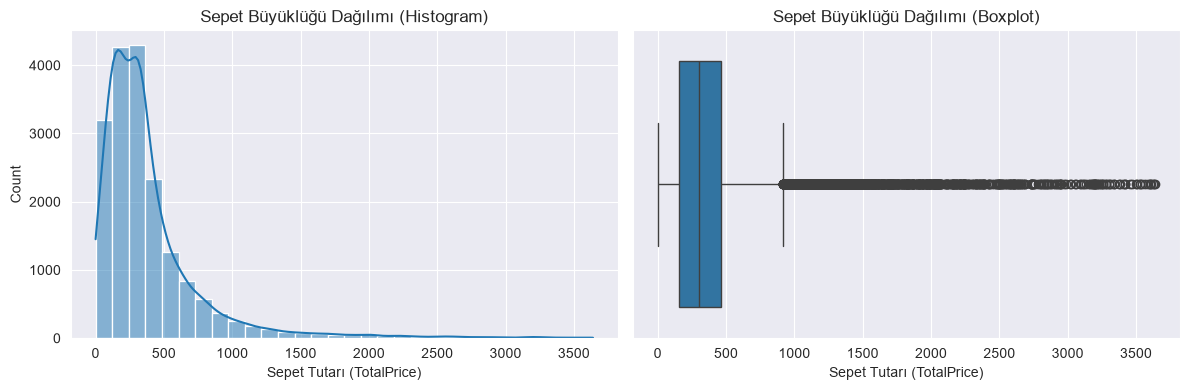

In [459]:
q_9_2 = osb['TotalPrice'].quantile(0.9)
filtered_rev_2 = osb[osb['TotalPrice'] <= q_9]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(filtered_rev_2['TotalPrice'], ax=axes[0], kde=True, bins=30)
axes[0].set_title('Sepet Büyüklüğü Dağılımı (Histogram)')
axes[0].set_xlabel('Sepet Tutarı (TotalPrice)')

sns.boxplot(x=filtered_rev_2['TotalPrice'], ax=axes[1])
axes[1].set_title('Sepet Büyüklüğü Dağılımı (Boxplot)')
axes[1].set_xlabel('Sepet Tutarı (TotalPrice)')

plt.tight_layout()
plt.show()